In [ ]:
!pip install -q librosa soundfile kaggle tqdm scikit-learn
print('installed')

installed


In [ ]:
# Set your Kaggle credentials securely before running this notebook.
# Do not hard-code API keys or commit kaggle.json to GitHub.
import os

# Set these as environment variables in your local environment, or configure
# the Kaggle API using ~/.kaggle/kaggle.json (kept outside this repository).
# os.environ["KAGGLE_USERNAME"] = os.getenv("KAGGLE_USERNAME", "")
# os.environ["KAGGLE_KEY"] = os.getenv("KAGGLE_KEY", "")


In [ ]:
# CREMA-D + TESS

!kaggle datasets download -d jayeshlandge/cremad -p /content/datasets/cremad --unzip
!kaggle datasets download -d ejlok1/toronto-emotional-speech-set-tess -p /content/datasets/tess --unzip

print('✅ Datasets downloaded')
!ls /content/datasets/cremad | head -5
!ls /content/datasets/tess | head -5

Dataset URL: https://www.kaggle.com/datasets/jayeshlandge/cremad
License(s): unknown
100% 451M/451M [00:07<00:00, 65.9MB/s]

Dataset URL: https://www.kaggle.com/datasets/ejlok1/toronto-emotional-speech-set-tess
License(s): Attribution-NonCommercial-NoDerivatives 4.0 International (CC BY-NC-ND 4.0)
100% 428M/428M [00:04<00:00, 110MB/s]

✅ Datasets downloaded
AudioWAV
tess toronto emotional speech set data
TESS Toronto emotional speech set data


In [ ]:
import os
import glob
from pathlib import Path

# ── Emotion maps ──────────────────────────────────────────────
CREMAD_EMOTION_MAP = {
    'ANG': 1, 'DIS': 1, 'FEA': 1,
    'HAP': 0, 'NEU': 0, 'SAD': 0,
}
TESS_EMOTION_MAP = {
    'angry': 1, 'disgust': 1, 'fear': 1,
    'happy': 0, 'neutral': 0, 'sad': 0, 'ps': 0,
}

# ── Auto-detect actual download paths ─────────────────────────
def find_wav_root(base):
    """Walk down until we find .wav files, return that folder."""
    for root, dirs, files in os.walk(base):
        if any(f.endswith('.wav') for f in files):
            return root
    return base

cremad_root = find_wav_root('/content/datasets/cremad')
tess_root   = find_wav_root('/content/datasets/tess')
print(f'CREMA-D wavs found under: {cremad_root}')
print(f'TESS wavs found under:    {tess_root}')

# ── File loaders ──────────────────────────────────────────────
def get_cremad_files():
    files_data = []
    for fp in glob.glob(f'{cremad_root}/**/*.wav', recursive=True) + \
               glob.glob(f'{cremad_root}/*.wav'):
        fname = Path(fp).stem
        parts = fname.split('_')
        if len(parts) >= 3:
            label = CREMAD_EMOTION_MAP.get(parts[2])
            if label is not None:
                files_data.append((fp, label))
    return files_data

def get_tess_files():
    files_data = []
    for fp in glob.glob(f'{tess_root}/**/*.wav', recursive=True) + \
               glob.glob(f'{tess_root}/*.wav'):
        folder = Path(fp).parent.name.lower()
        for emotion, label in TESS_EMOTION_MAP.items():
            if emotion in folder:
                files_data.append((fp, label))
                break
    return files_data

# ── Run ───────────────────────────────────────────────────────
cremad_data = get_cremad_files()
tess_data   = get_tess_files()

print(f'\nCREMA-D files found: {len(cremad_data)}')
print(f'TESS files found:    {len(tess_data)}')

all_data = cremad_data + tess_data
print(f'Total files:         {len(all_data)}')

stressed = sum(1 for _, l in all_data if l == 1)
calm     = sum(1 for _, l in all_data if l == 0)
print(f'Stressed (1): {stressed} | Calm (0): {calm}')

# Sanity check — show a sample filename from each
if cremad_data: print(f'\nSample CREMA-D: {Path(cremad_data[0][0]).name}')
if tess_data:   print(f'Sample TESS:    {Path(tess_data[0][0]).name}')

CREMA-D wavs found under: /content/datasets/cremad/AudioWAV
TESS wavs found under:    /content/datasets/tess/tess toronto emotional speech set data/TESS Toronto emotional speech set data/YAF_neutral

CREMA-D files found: 14884
TESS files found:    400
Total files:         15284
Stressed (1): 7626 | Calm (0): 7658

Sample CREMA-D: 1073_DFA_NEU_XX.wav
Sample TESS:    YAF_tape_neutral.wav


In [ ]:
import numpy as np
import librosa
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

SR = 16000          # sample rate
DURATION = 3        # seconds (3s is faster than 10s and still works great)
N_MFCC = 13         # number of MFCC coefficients
MAX_LEN = 130       # fixed sequence length for LSTM (frames)

def extract_features(file_path):
    """
    Returns a 2D array of shape (MAX_LEN, 39) — the LSTM input.
    Features per frame: 13 MFCCs + 13 delta MFCCs + 13 delta-delta MFCCs
    """
    try:
        y, sr = librosa.load(file_path, sr=SR, duration=DURATION)

        # Pad or trim to fixed length
        target_len = SR * DURATION
        if len(y) < target_len:
            y = np.pad(y, (0, target_len - len(y)))
        else:
            y = y[:target_len]

        # Extract MFCCs (shape: n_mfcc x time)
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)

        # Delta and delta-delta
        delta_mfcc  = librosa.feature.delta(mfcc)
        delta2_mfcc = librosa.feature.delta(mfcc, order=2)

        # Stack: shape (39, time)
        combined = np.vstack([mfcc, delta_mfcc, delta2_mfcc])

        # Transpose to (time, 39), then fix to MAX_LEN
        combined = combined.T  # (time, 39)
        if combined.shape[0] < MAX_LEN:
            pad = np.zeros((MAX_LEN - combined.shape[0], combined.shape[1]))
            combined = np.vstack([combined, pad])
        else:
            combined = combined[:MAX_LEN]

        return combined.astype(np.float32)
    except Exception as e:
        return None

print('🔄 Extracting features... (grab a coffee ☕)')

X = []
y = []
failed = 0

for file_path, label in tqdm(all_data, desc='Extracting'):
    features = extract_features(file_path)
    if features is not None:
        X.append(features)
        y.append(label)
    else:
        failed += 1

X = np.array(X)  # shape: (N, MAX_LEN, 39)
y = np.array(y)

print(f'\n✅ Done! X shape: {X.shape}, y shape: {y.shape}')
print(f'Failed: {failed}')
print(f'Stressed: {y.sum()} | Calm: {(y==0).sum()}')

🔄 Extracting features... (grab a coffee ☕)


Extracting: 100%|██████████| 15284/15284 [03:48<00:00, 66.96it/s]



✅ Done! X shape: (15284, 130, 39), y shape: (15284,)
Failed: 0
Stressed: 7626 | Calm: 7658


In [ ]:
np.save('/content/X_features.npy', X)
np.save('/content/y_labels.npy', y)
print('✅ Features saved to /content/')

# To reload later:
# X = np.load('/content/X_features.npy')
# y = np.load('/content/y_labels.npy')


✅ Features saved to /content/


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split: 70% train, 15% val, 15% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.176, random_state=42, stratify=y_temp
    # 0.176 of 0.85 ≈ 0.15 of total
)

print(f'Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}')

# Normalize using train stats (per-feature across time)
# Reshape to 2D for scaler, then back to 3D
n_train, seq_len, n_feat = X_train.shape

scaler = StandardScaler()
X_train_2d = X_train.reshape(-1, n_feat)
scaler.fit(X_train_2d)

X_train = scaler.transform(X_train.reshape(-1, n_feat)).reshape(X_train.shape)
X_val   = scaler.transform(X_val.reshape(-1, n_feat)).reshape(X_val.shape)
X_test  = scaler.transform(X_test.reshape(-1, n_feat)).reshape(X_test.shape)

# Save scaler for inference
import pickle
with open('/content/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print('✅ Data normalized and scaler saved')

Train: (10704, 130, 39) | Val: (2287, 130, 39) | Test: (2293, 130, 39)
✅ Data normalized and scaler saved


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

print(f'TF version: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')

def build_lstm_model(input_shape):
    model = models.Sequential([
        # Input
        layers.Input(shape=input_shape),

        # LSTM Layer 1
        layers.LSTM(64, return_sequences=True, dropout=0.2, recurrent_dropout=0.1),
        layers.BatchNormalization(),

        # LSTM Layer 2
        layers.LSTM(64, return_sequences=False, dropout=0.2),
        layers.BatchNormalization(),

        # Dense head
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),

        # Output
        layers.Dense(1, activation='sigmoid')
    ])
    return model

input_shape = (X_train.shape[1], X_train.shape[2])  # (MAX_LEN, 39)
model = build_lstm_model(input_shape)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

TF version: 2.19.0
GPU: []


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 130, 64)        │        26,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 130, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,273 (243.25 KB)

 Trainable params: 62,017 (242.25 KB)

 Non-trainable params: 256 (1.00 KB)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

print(f'TF version: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')

def build_lstm_model(input_shape):
    model = models.Sequential([
        # Input
        layers.Input(shape=input_shape),

        # LSTM Layer 1
        layers.LSTM(64, return_sequences=True, dropout=0.2, recurrent_dropout=0.1),
        layers.BatchNormalization(),

        # LSTM Layer 2
        layers.LSTM(64, return_sequences=False, dropout=0.2),
        layers.BatchNormalization(),

        # Dense head
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),

        # Output
        layers.Dense(1, activation='sigmoid')
    ])
    return model

input_shape = (X_train.shape[1], X_train.shape[2])  # (MAX_LEN, 39)
model = build_lstm_model(input_shape)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

TF version: 2.19.0
GPU: []


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 130, 64)        │        26,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 130, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,273 (243.25 KB)

 Trainable params: 62,017 (242.25 KB)

 Non-trainable params: 256 (1.00 KB)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Handle class imbalance
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print(f'Class weights: {class_weight_dict}')

# Callbacks
cb_list = [
    callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        '/content/best_lstm_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

# Train!
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict,
    callbacks=cb_list,
    verbose=1
)

print('\n✅ Training complete!')

Class weights: {0: np.float64(0.997948909192616), 1: np.float64(1.002059539412095)}
Epoch 1/50
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step - accuracy: 0.5050 - loss: 0.7890
Epoch 1: val_accuracy improved from None to 0.50109, saving model to /content/best_lstm_model.keras

Epoch 1: finished saving model to /content/best_lstm_model.keras
335/335 ━━━━━━━━━━━━━━━━━━━━ 88s 212ms/step - accuracy: 0.5080 - loss: 0.7357 - val_accuracy: 0.5011 - val_loss: 0.6926 - learning_rate: 0.0010
Epoch 2/50
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.5203 - loss: 0.6983
Epoch 2: val_accuracy improved from 0.50109 to 0.59160, saving model to /content/best_lstm_model.keras

Epoch 2: finished saving model to /content/best_lstm_model.keras
335/335 ━━━━━━━━━━━━━━━━━━━━ 70s 209ms/step - accuracy: 0.5402 - loss: 0.6920 - val_accuracy: 0.5916 - val_loss: 0.6782 - learning_rate: 0.0010
Epoch 3/50
335/335 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.5711 - loss: 0.6819
Epoch 3: val_accuracy improve

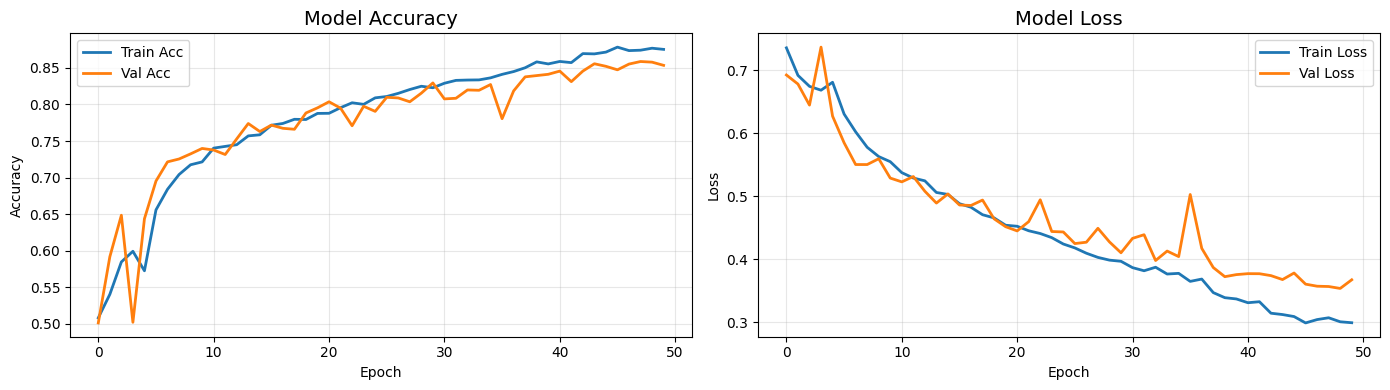

✅ Plot saved


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Accuracy
axes[0].plot(history.history['accuracy'], label='Train Acc', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Val Acc', linewidth=2)
axes[0].set_title('Model Accuracy', fontsize=14)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(history.history['loss'], label='Train Loss', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
axes[1].set_title('Model Loss', fontsize=14)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/content/training_history.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Plot saved')

         LSTM TEST RESULTS
              precision    recall  f1-score   support

        Calm       0.86      0.85      0.85      1149
    Stressed       0.85      0.86      0.85      1144

    accuracy                           0.85      2293
   macro avg       0.85      0.85      0.85      2293
weighted avg       0.85      0.85      0.85      2293

ROC-AUC Score: 0.9242
Avg Inference Time: 4.92 ms/sample


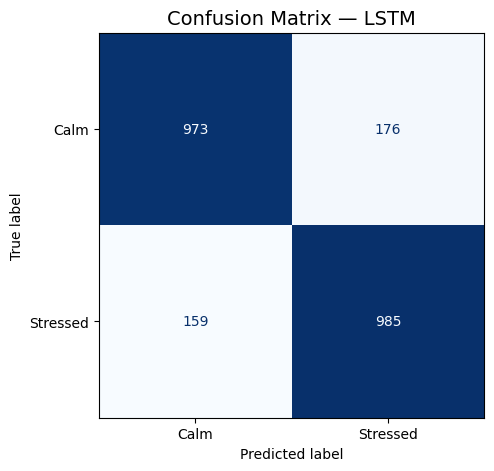

In [ ]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, ConfusionMatrixDisplay
)
import time

# Load best model
best_model = tf.keras.models.load_model('/content/best_lstm_model.keras')

# Inference time test
start = time.time()
y_prob = best_model.predict(X_test, batch_size=32, verbose=0)
elapsed = (time.time() - start) * 1000 / len(X_test)

y_pred = (y_prob > 0.5).astype(int).flatten()

print('='*50)
print('         LSTM TEST RESULTS')
print('='*50)
print(classification_report(y_test, y_pred, target_names=['Calm', 'Stressed']))
print(f'ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}')
print(f'Avg Inference Time: {elapsed:.2f} ms/sample')
print('='*50)

# Confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Calm', 'Stressed'])
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Confusion Matrix — LSTM', fontsize=14)
plt.savefig('/content/confusion_matrix_lstm.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, f1_score

# Flatten: take mean across time axis → shape (N, 39)
X_train_flat = X_train.mean(axis=1)
X_val_flat   = X_val.mean(axis=1)
X_test_flat  = X_test.mean(axis=1)

results = {}

# --- Random Forest ---
print('🌲 Training Random Forest...')
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1, class_weight='balanced')
rf.fit(X_train_flat, y_train)
rf_pred = rf.predict(X_test_flat)
rf_f1   = f1_score(y_test, rf_pred, average='macro')
results['Random Forest'] = rf_f1
print(f'Random Forest F1: {rf_f1:.4f}')
print(classification_report(y_test, rf_pred, target_names=['Calm', 'Stressed']))

# --- SVM ---
print('\n🔷 Training SVM...')
svm = SVC(kernel='rbf', C=10, gamma='scale', class_weight='balanced', random_state=42)
svm.fit(X_train_flat, y_train)
svm_pred = svm.predict(X_test_flat)
svm_f1   = f1_score(y_test, svm_pred, average='macro')
results['SVM'] = svm_f1
print(f'SVM F1: {svm_f1:.4f}')
print(classification_report(y_test, svm_pred, target_names=['Calm', 'Stressed']))

# Get LSTM F1 for comparison
lstm_f1 = f1_score(y_test, y_pred, average='macro')
results['LSTM (ours)'] = lstm_f1
print(f'\n🏆 LSTM F1: {lstm_f1:.4f}')

🌲 Training Random Forest...
Random Forest F1: 0.9032
              precision    recall  f1-score   support

        Calm       0.90      0.91      0.90      1149
    Stressed       0.91      0.90      0.90      1144

    accuracy                           0.90      2293
   macro avg       0.90      0.90      0.90      2293
weighted avg       0.90      0.90      0.90      2293


🔷 Training SVM...
SVM F1: 0.7857
              precision    recall  f1-score   support

        Calm       0.76      0.84      0.80      1149
    Stressed       0.82      0.74      0.77      1144

    accuracy                           0.79      2293
   macro avg       0.79      0.79      0.79      2293
weighted avg       0.79      0.79      0.79      2293


🏆 LSTM F1: 0.8539


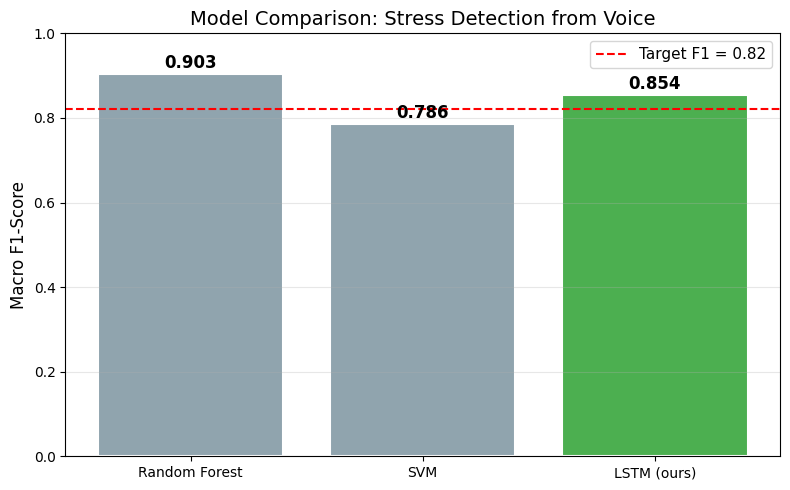

✅ Comparison chart saved


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models_names = list(results.keys())
f1_scores    = list(results.values())
colors = ['#4CAF50' if n == 'LSTM (ours)' else '#90A4AE' for n in models_names]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(models_names, f1_scores, color=colors, edgecolor='white', linewidth=1.5)

for bar, score in zip(bars, f1_scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{score:.3f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.axhline(y=0.82, color='red', linestyle='--', linewidth=1.5, label='Target F1 = 0.82')
ax.set_ylim(0, 1.0)
ax.set_ylabel('Macro F1-Score', fontsize=12)
ax.set_title('Model Comparison: Stress Detection from Voice', fontsize=14)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('/content/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Comparison chart saved')

In [ ]:
import pickle
import zipfile

# Save baseline models
with open('/content/rf_model.pkl', 'wb') as f:
    pickle.dump(rf, f)
with open('/content/svm_model.pkl', 'wb') as f:
    pickle.dump(svm, f)

# Zip everything
files_to_zip = [
    '/content/best_lstm_model.keras',
    '/content/scaler.pkl',
    '/content/rf_model.pkl',
    '/content/svm_model.pkl',
    '/content/training_history.png',
    '/content/confusion_matrix_lstm.png',
    '/content/model_comparison.png',
]

with zipfile.ZipFile('/content/stress_detection_models.zip', 'w') as zf:
    for f in files_to_zip:
        if os.path.exists(f):
            zf.write(f, os.path.basename(f))

print('✅ All models saved to stress_detection_models.zip')

# Download
from google.colab import files
files.download('/content/stress_detection_models.zip')

✅ All models saved to stress_detection_models.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>